# The decoders

The decoder is the local interpolator that predicts inside each cell of a partition. Spatialize offers
several, each good at something different, whether the sharpest map, intervals that cover the truth,
the values an atom must keep, or the geometry of the field. Here we run them side by side on
fields whose truth we know, each decoder on a field it suits.

## Learning goals

- The two families of decoders, averaging and drawing, and what each does to the members.
- The weights behind them, from the cell mean to the adaptive and sharpened IDW and kriging.
- How to compare decoders by the accuracy of the map, the coverage of the intervals and the
  roughness of the map.
- Which decoder to choose for which purpose.

*Which local interpolator should an ensemble use, and for what?*

## The idea

Every decoder starts from non-negative weights on the data of the cell. An **averaging** decoder
returns their weighted mean, so its members vary only because the cells vary. Its maps are smooth,
while its intervals miss the dispersion of the values inside a cell. A **drawing** decoder returns one
of the cell's data, drawn with the same weights, afresh at every location and partition. Its mean is
the averaging decoder's prediction, while its spread adds the weighted dispersion of the cell, so the
ensemble carries both sources of uncertainty, every member being a value that was observed.

The weights give the decoders their names.

- `cellmean`, equal weights, all the spatial detail coming from the partition.
- `idw`, the inverse of the distance to a power, for fields without a preferred direction.
- `kriging`, the ordinary kriging weights of an isotropic variogram whose model, nugget and range the
  Pareto search chooses, for smooth fields without a preferred direction.
- `adaptiveidw`, IDW with an exponent and an anisotropy fitted in every cell, for fields whose
  direction is unknown or changes.
- `sharpidw`, the adaptive IDW with more weight on the data the rest of the cell predicts badly.
- `draw` and the weighted draws `wdraw_idw`, `wdraw_kriging`, `wdraw_adaptiveidw`, `wdraw_sharpidw`.

The theory page [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) gives the
formulas and the reasons.

## Step by step

### Three measures

We judge each decoder on the whole grid against the truth by three numbers.

- The **mean absolute error** of the map, the mean of the members.
- The **coverage** of the 90 % interval of the members, the share of the grid where the truth lies
  between their 5 % and 95 % quantiles. A calibrated ensemble covers 90 %.
- The **roughness** of the map, the mean absolute difference between neighbouring grid values,
  relative to that of the truth. An ensemble map averages over partitions, so it comes out smoother
  than the field, by an amount this ratio gives.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

import spatialize
from spatialize.data import load_simulated_anisotropic_data, load_elevation_walker_lake
from spatialize.evaluation import MAE
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
import spatialize.gs.esi.aggfunction as af
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen")

def measures(result, truth):
    estimate, members = result.estimation(), result.esi_samples()
    low, high = np.nanpercentile(members, [5, 95], axis=-1)
    roughness = np.abs(np.diff(estimate, axis=0)).mean() / np.abs(np.diff(truth, axis=0)).mean()
    return {"true MAE": round(MAE(truth.ravel(), estimate.ravel()), 4),
            "90 % coverage": round(np.mean((truth >= low) & (truth <= high)), 2),
            "roughness": round(roughness, 2)}

### A field with a direction

The first field is the anisotropic Gaussian simulation of the tutorial on the Pareto search, 400 data
on a 200 × 200 grid. Its correlation is longer in one direction, so we compare the decoders that fit a
direction in each cell, the adaptive and sharpened IDW, with the cell mean and the draws. A quick
Pareto search with the adaptive IDW, read at its knee, sets the granularity.

In [2]:
(samples, _), _, _, grid = load_simulated_anisotropic_data()
points, values = samples[["x", "y"]].values, samples["sim1"].values
truth = grid["sim1"].values.reshape(200, 200).T            # truth[i, j] at x = i, y = j
xi = np.stack(np.meshgrid(np.arange(200.0), np.arange(200.0), indexing="ij"))

alpha = esi_pareto_hparams_search(points, values, local_interpolator="adaptiveidw", n_partitions=[100],
                                  alpha=[0.85, 0.9, 0.95, 0.98], k=5, scoring=sf.mae,
                                  seed=0).best_result(strategy="knee")["alpha"]
print(f"alpha at the knee {alpha}")

alpha at the knee 0.95


In [3]:
decoders = {"adaptiveidw": {}, "sharpidw": {"kappa_g": 0.0}, "cellmean": {}, "draw": {},
            "wdraw_adaptiveidw": {}}
results = {name: esi_griddata(points, values, xi, local_interpolator=name, n_partitions=100, alpha=alpha,
                              seed=0, **params)
           for name, params in decoders.items()}
pd.DataFrame({name: measures(r, truth) for name, r in results.items()}).T

,true MAE,90 % coverage,roughness
adaptiveidw,0.4525,0.60,0.11
sharpidw,0.4504,0.63,0.11
cellmean,0.5185,0.62,0.04
draw,0.5208,0.88,0.18
wdraw_adaptiveidw,0.4539,0.75,0.16


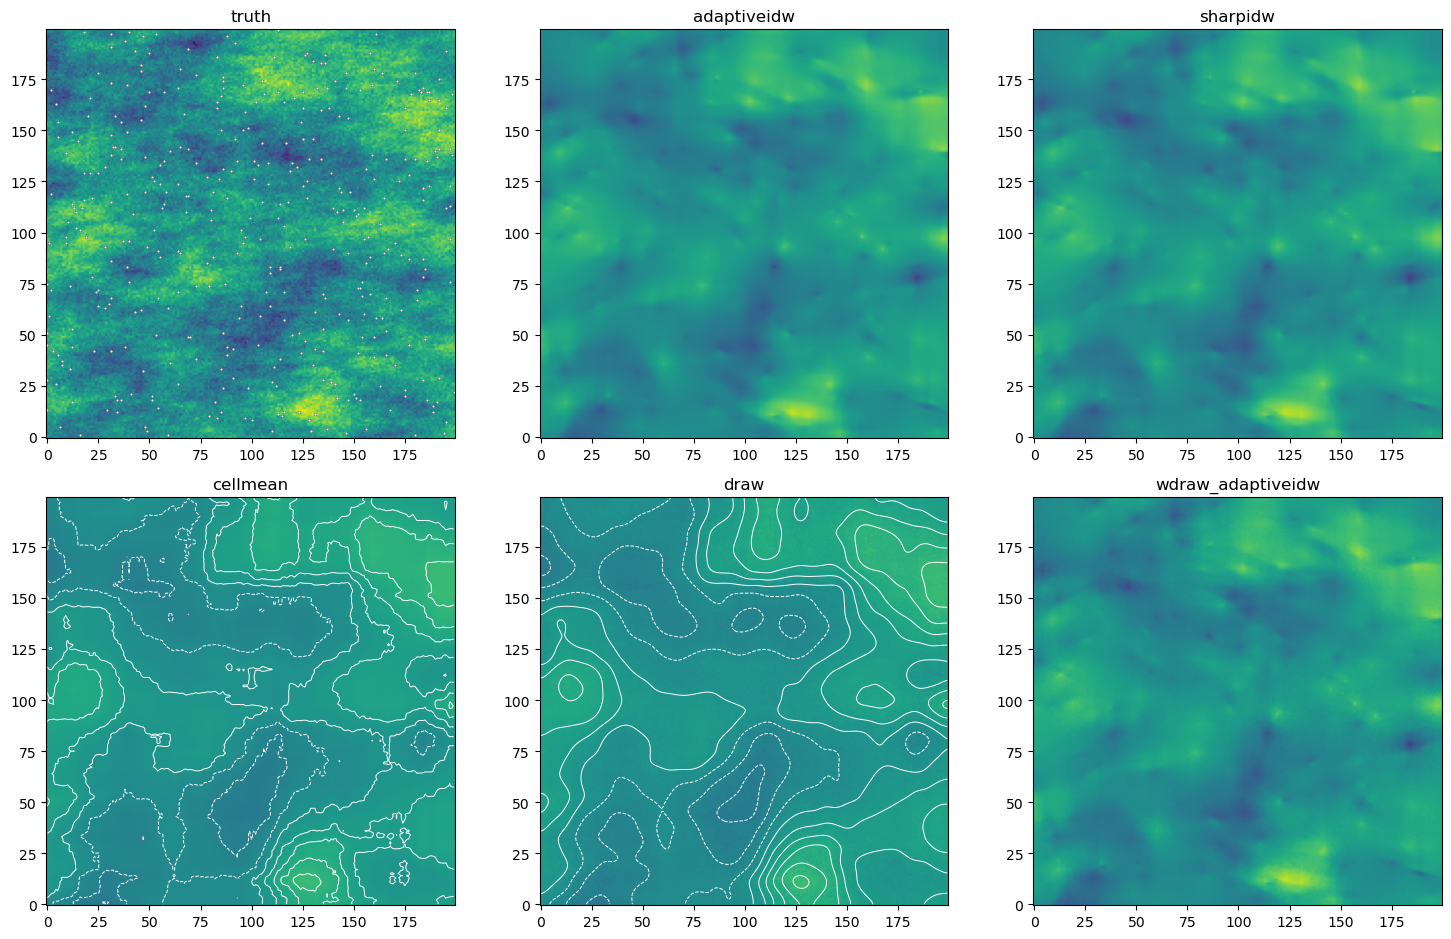

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
panels = [("truth", truth)] + [(name, r.estimation()) for name, r in results.items()]
for ax, (name, field) in zip(axes.ravel(), panels):
    ax.imshow(field.T, origin="lower", cmap="viridis", vmin=truth.min(), vmax=truth.max())
    if name in ("cellmean", "draw"):
        # the draw's map is rough, so its contour lines are drawn on it smoothed over a few cells
        lines = gaussian_filter(field, 3) if name == "draw" else field
        ax.contour(lines.T, levels=8, colors="white", linewidths=0.7)
    ax.set_title(name)
axes[0, 0].scatter(points[:, 0], points[:, 1], s=4, c="white", edgecolors="black", linewidths=0.2)
plt.tight_layout()
plt.show()

The sharpened IDW, with only its boost of the data the cell predicts badly (`kappa_g=0`), gives the
best map, a little ahead of the adaptive IDW. The cell mean loses most of the contrast. At this
granularity its cells hold many data, whose mean flattens the field, all its detail coming from the
partitions. The uniform draw covers close to the nominal 90 %, although its map is the least accurate
of all. Both keep the spatial structure of the field, since their contour lines, drawn in white,
follow the patches of the truth while the amplitude shrinks (those of the draw on its map smoothed
over a few cells, its members being rough). The cell mean thus suits the geometry of the field more
than its values. The weighted draw keeps almost the adaptive map while covering far more than the
averaging decoders. The draws also give the
roughest maps, since their members are observed values.

### A field without a direction

Plain IDW and kriging weigh the data by distance alone, the same in every direction, so a fair test
needs a field without a preferred direction. This one is an isotropic Gaussian field with an
exponential covariance of range 8, simulated on a 64 × 64 grid, with 300 of its nodes as data. The
kriging decoder takes an isotropic variogram whose model, nugget and range are hyperparameters like any
other. The Pareto search chooses them at the same granularity, without a variogram model fitted to the
data and without the field's own covariance.

In [5]:
m = 64
nodes = np.stack(np.meshgrid(np.arange(m), np.arange(m), indexing="ij"), -1).reshape(-1, 2).astype(float)
distance = np.sqrt(((nodes[:, None, :] - nodes[None, :, :]) ** 2).sum(-1))
rng = np.random.default_rng(101)
field = np.linalg.cholesky(np.exp(-distance / 8.0) + 1e-8 * np.eye(len(nodes))) @ rng.standard_normal(len(nodes))
picked = rng.choice(len(nodes), 300, replace=False)
iso_points, iso_values, iso_truth = nodes[picked], field[picked], field.reshape(m, m)
iso_xi = np.stack(np.meshgrid(np.arange(m, dtype=float), np.arange(m, dtype=float), indexing="ij"))

iso_alpha = esi_pareto_hparams_search(iso_points, iso_values, local_interpolator="idw", n_partitions=[100],
                                      alpha=[0.9, 0.95, 0.98, 0.99], exponent=[2.0], k=5, scoring=sf.mae,
                                      seed=0).best_result(strategy="knee")["alpha"]
knee = esi_pareto_hparams_search(iso_points, iso_values, local_interpolator="kriging", n_partitions=[100],
                                 alpha=[iso_alpha], model=["spherical", "exponential", "gaussian"],
                                 nugget=[0.0, 0.1, 0.3], range=[4.0, 8.0, 16.0, 32.0, 64.0], sill=[1.0],
                                 k=5, scoring=sf.mae, seed=0).best_result(strategy="knee")
variogram = {key: knee[key] for key in ("model", "nugget", "range", "sill")}
print("kriging decoder, chosen by the Pareto search", variogram)
iso_decoders = {"idw": {"exponent": 2.0}, "kriging": variogram, "wdraw_idw": {"exponent": 2.0},
                "wdraw_kriging": variogram, "cellmean": {}}
iso_results = {name: esi_griddata(iso_points, iso_values, iso_xi, local_interpolator=name, n_partitions=100,
                                  alpha=iso_alpha, seed=0, **params)
               for name, params in iso_decoders.items()}
print(f"alpha at the knee {iso_alpha}")
pd.DataFrame({name: measures(r, iso_truth) for name, r in iso_results.items()}).T

kriging decoder, chosen by the Pareto search {'model': 'gaussian', 'nugget': 0.1, 'range': 8.0, 'sill': 1.0}


alpha at the knee 0.98


,true MAE,90 % coverage,roughness
idw,0.3972,0.61,0.34
kriging,0.3942,0.68,0.34
wdraw_idw,0.3978,0.66,0.35
wdraw_kriging,0.3965,0.64,0.34
cellmean,0.4220,0.73,0.25


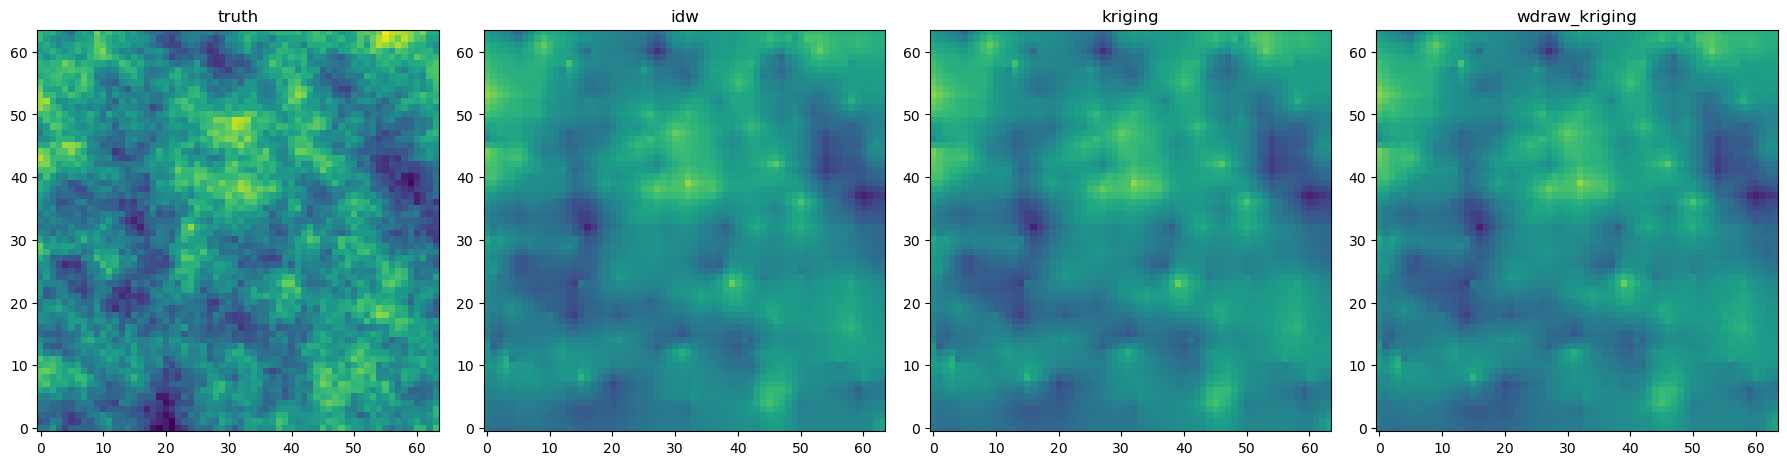

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (name, f) in zip(axes, [("truth", iso_truth)] + [(n, iso_results[n].estimation()) for n in ("idw", "kriging", "wdraw_kriging")]):
    ax.imshow(f.T, origin="lower", cmap="viridis", vmin=iso_truth.min(), vmax=iso_truth.max())
    ax.set_title(name)
plt.tight_layout()
plt.show()

With the variogram the search chooses, a Gaussian model of range 8 with a small nugget, kriging gives
the best map of the isotropic field, by a small margin over IDW. The search reaches that map without the
field's covariance, an exponential model. The weighted draws keep the maps. The draw of IDW widens its intervals, while that of kriging
does not on this field. The cell mean
is the least accurate map here, since the field varies within the cells, while its intervals cover
the most.

### A value that must stay exact

Walker Lake's elevation has an *atom*, since the lake is flat at one level over about a seventh of
the area. An averaging decoder mixes the lake data with the slope data in any cell that reaches the
shore, so it raises the lake there. A drawing decoder returns observed values, so the median of its
members falls on the lake level wherever most of them are lake data.

In [7]:
wl_samples, wl_grid = load_elevation_walker_lake()
wl_points, wl_values = wl_samples[["x", "y"]].values, wl_samples["elevation"].values
xs, ys = np.sort(wl_grid["x"].unique()), np.sort(wl_grid["y"].unique())
wl_truth = wl_grid.sort_values(["x", "y"])["elevation"].values.reshape(len(xs), len(ys))
wl_xi = np.stack(np.meshgrid(xs, ys, indexing="ij"))
level = wl_values.min()
lake = np.isclose(wl_truth, level, atol=0.05)

rows, readings = {}, {}
for name in ("adaptiveidw", "wdraw_adaptiveidw"):
    r = esi_griddata(wl_points, wl_values, wl_xi, local_interpolator=name, n_partitions=100, alpha=0.95, seed=0)
    for reading, estimate in (("mean", r.estimation()), ("median", r.re_estimate(af.median))):
        readings[f"{name}, {reading}"] = estimate
        at_level = np.isclose(estimate, level, atol=0.05)
        rows[f"{name}, {reading}"] = {"lake cells at the lake level": round(at_level[lake].mean(), 2),
                                     "lake cells raised by more than 1 m": round((estimate[lake] - level > 1).mean(), 2),
                                     "other cells put at the lake level": round(at_level[~lake].mean(), 3)}
print(f"lake level {level:.1f} m, {lake.mean():.0%} of the grid")
pd.DataFrame(rows).T

lake level 1194.3 m, 15% of the grid


,lake cells at the lake level,lake cells raised by more than 1 m,other cells put at the lake level
"adaptiveidw, mean",0.21,0.41,0.000
"adaptiveidw, median",0.78,0.12,0.001
"wdraw_adaptiveidw, mean",0.39,0.38,0.000
"wdraw_adaptiveidw, median",0.92,0.06,0.006


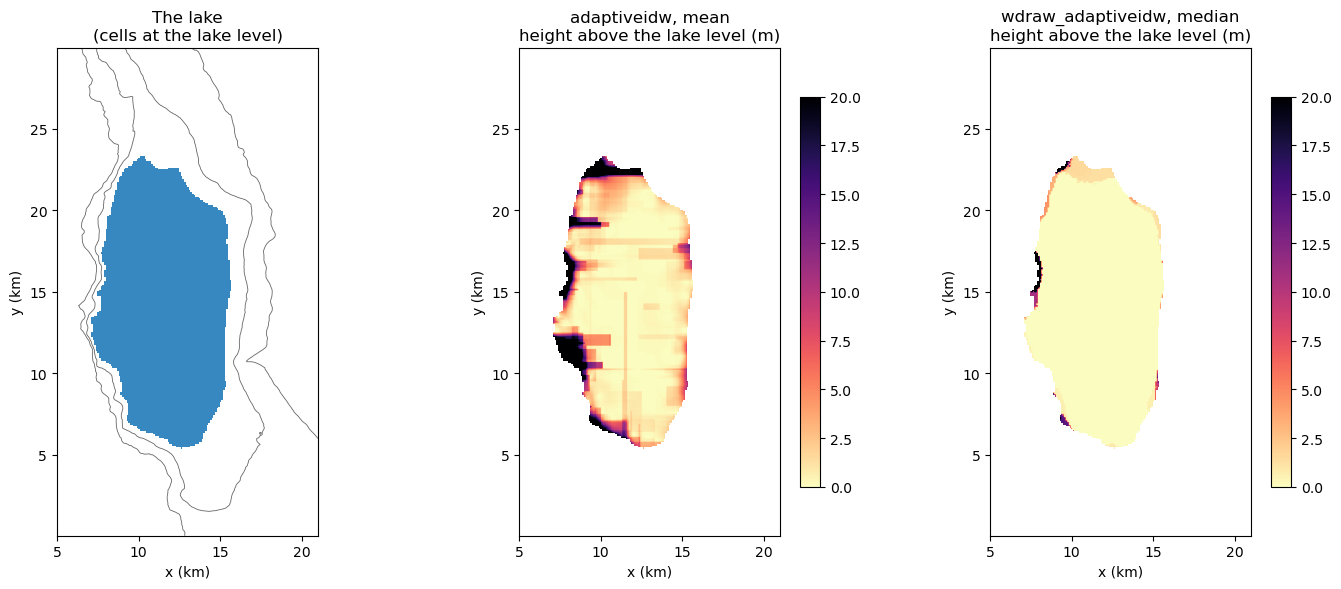

In [8]:
extent = (xs[0], xs[-1], ys[0], ys[-1])
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
axes[0].imshow(np.where(lake, 1.0, np.nan).T, origin="lower", extent=extent, cmap="Blues", vmin=0, vmax=1.5)
axes[0].contour(xs, ys, wl_truth.T, levels=[level + 25, level + 100], colors="0.4", linewidths=0.6)
axes[0].set_title("The lake\n(cells at the lake level)")
for ax, name in zip(axes[1:], ("adaptiveidw, mean", "wdraw_adaptiveidw, median")):
    raised = np.where(lake, readings[name] - level, np.nan)
    im = ax.imshow(raised.T, origin="lower", extent=extent, cmap="magma_r", vmin=0, vmax=20)
    ax.set_title(f"{name}\nheight above the lake level (m)")
    fig.colorbar(im, ax=ax, shrink=0.8)
for ax in axes:
    ax.set_xlim(5, 21); ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)")
plt.tight_layout()
plt.show()

The mean of the averaging decoder raises a band along the western and northern shores, below the
steepest slopes, besides straight streaks across the lake where a cell of some partitions reaches the slopes. The median of
the weighted draw keeps the lake flat almost to the water's edge, while away from the lake hardly any
cell falls to the lake level under either reading. Zeros of rainfall, detection limits and any value a
field holds over an area behave the same way, so a draw read through its median keeps the atom.

### Choosing by purpose

| Purpose | Decoder |
|---|---|
| a map of best values | `adaptiveidw`, or `sharpidw` with `kappa_g=0` |
| intervals and probabilities of exceedance | a weighted draw, `wdraw_sharpidw` or `wdraw_adaptiveidw` |
| a variable with an atom (zeros, detection limits) | `draw` or a weighted draw, read through the median |
| a heavy-tailed variable | a weighted draw, read through the median |
| the latent geometry of the field | `cellmean` |
| a smooth field without a preferred direction | `kriging`, its variogram chosen by the Pareto search |
| a fast baseline on a field without a direction | `idw` |

## Pitfalls

- **An isotropic decoder on a field with a direction.** IDW and kriging with an isotropic variogram draw
  round bull's-eyes around the data where the field is elongated. Use the adaptive decoders there.
- **Kriging on skewed data.** Its weights can be negative, so its estimate
  can leave the range of the data. On skewed or heavy-tailed variables prefer a weighted draw.
- **Judging a drawing decoder by its map alone.** Its members are rough by design, since each is an
  observed value. Read it through the quantiles or the median of its members, which give its law.
- **Comparing decoders at different granularities.** Choose `alpha` once, here at the knee of the
  Pareto frontier, and compare the decoders at it.

## Try it yourself

1. Add `"wdraw_sharpidw"` to the decoders of the first field and compare its coverage with the others.
2. Give kriging a wrong range (8 or 60) on the isotropic field and watch its map and error.
3. Run `sharpidw` with its default `kappa_g` and compare it with `kappa_g=0`.
4. Write a decoder of your own in Python with `local_interpolator="custom"` (the tutorial *A decoder in
   Python and numba*).

## Next

- *The probabilistic decoders*, for the draws and the laws they give, in depth.
- *Uncertainty at a location*, to read the members of any decoder as a law.
- *Choosing an ensemble with the Pareto search*, for the granularity used here.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html) (theory).